# AI Model Experiment & Evaluation

**Experiment 1: TF-IDF + Logistic Regression** vs **Experiment 2: Gemini API (zero-shot)**.

## 1. Problem Statement

**Objective:** Membandingkan model klasifikasi sentimen berbasis Scikit-learn dan LLM Gemini untuk mengklasifikasikan ulasan pelanggan e-commerce.

**Target/label:** `sentiment`: `positif` atau `negatif`. Input utama `review_text`.

**Batasan/asumsi:** Dataset berisi ulasan berbahasa Indonesia dengan hanya dua kelas; data kecil (200 baris) dan banyak teks duplikat (40 teks unik). Kedua pendekatan dievaluasi pada test set identik dan *tidak boleh menggunakan label test set dalam prompt*.


## 2. Import Library & Load Dataset

In [ ]:
from pathlib import Path
import os, json, re, time
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)
from dotenv import load_dotenv
from google import genai
from google.genai import types

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebook' else Path.cwd()
load_dotenv(PROJECT_ROOT / '.env')  # API key lokal, tidak masuk GitHub
DATA_PATH = PROJECT_ROOT / 'data' / 'customer_reviews_sentiment.csv'
DOCS_PATH = PROJECT_ROOT / 'documentation'
DOCS_PATH.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.exists(), f'Dataset tidak ditemukan: {DATA_PATH}'

df = pd.read_csv(DATA_PATH, encoding='utf-8-sig')
assert {'review_id','product_name','review_text','sentiment'}.issubset(df.columns)
assert df[['review_text','sentiment']].notna().all().all(), 'Ada teks/label kosong.'
assert set(df['sentiment'].unique()) == {'positif','negatif'}
print('Jumlah data:',len(df))
print('Jumlah teks unik:',df['review_text'].nunique())
print('Distribusi label:\n',df['sentiment'].value_counts())
display(df.head())


Jumlah data: 200
Jumlah teks unik: 40
Distribusi label:
 sentiment
positif    110
negatif     90
Name: count, dtype: int64


,review_id,product_name,review_text,sentiment
0,1,Kemeja Flanel,Pelayanan lambat dan tidak responsif saat diko...,negatif
1,2,Case HP,"Puas banget belanja disini, proses cepat dan b...",positif
2,3,Rice Cooker,"Terima kasih seller, barangnya awet dan sesuai...",positif
3,4,Case HP,Warna produk berbeda jauh dari foto di listing.,negatif
4,5,Headset Bluetooth,"Terima kasih seller, barangnya awet dan sesuai...",positif


## 3. Menyiapkan Train/Test Split

In [ ]:
conflicting = df.groupby('review_text')['sentiment'].nunique()
assert conflicting.max() == 1, 'Teks identik mempunyai label yang berbeda.'

unique_df = df[['review_text','sentiment']].drop_duplicates(subset=['review_text'])
train_texts, test_texts = train_test_split(
    unique_df['review_text'], test_size=0.20, random_state=42,
    stratify=unique_df['sentiment']
)
train_df = df.loc[df['review_text'].isin(set(train_texts))].copy()
test_df  = df.loc[df['review_text'].isin(set(test_texts))].copy()

X_train, y_train = train_df['review_text'], train_df['sentiment']
X_test, y_test = test_df['review_text'], test_df['sentiment']
assert set(X_train).isdisjoint(set(X_test)), 'Terjadi leakage antar kelompok!'
assert len(train_df) + len(test_df) == len(df)
print('Training:',len(X_train),'baris /',X_train.nunique(),'teks unik')
print('Testing:',len(X_test),'baris /',X_test.nunique(),'teks unik')
print('Label testing:\n',y_test.value_counts())


Training: 158 baris / 32 teks unik
Testing: 42 baris / 8 teks unik
Label testing:
 sentiment
negatif    24
positif    18
Name: count, dtype: int64


## 4. Pendekatan 1 — Model Klasik (Scikit-learn)

### 4.1 Preprocessing & Feature Extraction

In [ ]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), lowercase=True)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)
print('Jumlah fitur TF-IDF:',X_train_vec.shape[1])


Jumlah fitur TF-IDF: 329


### 4.2 Training Model

In [4]:
classic_start = time.perf_counter()
clf = LogisticRegression(max_iter=1000, random_state=42)
clf.fit(X_train_vec,y_train)
classic_training_sec = time.perf_counter()-classic_start
print(f'Training selesai: {classic_training_sec:.4f} detik')


Training selesai: 0.0149 detik


### 4.3 Prediksi pada Test Set

In [5]:
classic_pred_start = time.perf_counter()
y_pred_classic = clf.predict(X_test_vec)
classic_predict_sec = time.perf_counter()-classic_pred_start
print('Contoh prediksi:')
display(pd.DataFrame({'ulasan':X_test.values,'label_asli':y_test.values,
                      'prediksi_klasik':y_pred_classic}).head(8))


Contoh prediksi:


,ulasan,label_asli,prediksi_klasik
0,"Puas banget belanja disini, proses cepat dan b...",positif,positif
1,"Terima kasih seller, barangnya awet dan sesuai...",positif,positif
2,"Terima kasih seller, barangnya awet dan sesuai...",positif,positif
3,"Pengiriman lambat sekali, sudah dua minggu bel...",negatif,negatif
4,"Pengiriman lambat sekali, sudah dua minggu bel...",negatif,negatif
5,"Puas banget belanja disini, proses cepat dan b...",positif,positif
6,Respon penjual lambat dan terkesan tidak pedul...,negatif,positif
7,"Pengiriman lambat sekali, sudah dua minggu bel...",negatif,negatif


## 5. Pendekatan 2 — LLM API (Gemini)

### 5.1 Setup API

In [ ]:
API_KEY = os.environ.get('GEMINI_API_KEY')
if not API_KEY:
    raise RuntimeError('GEMINI_API_KEY belum tersedia. Isi file .env di root project, lalu restart kernel.')

client = genai.Client(api_key=API_KEY)
MODEL_NAME = 'gemini-3.5-flash-lite'
TEMPERATURE = 0.0 
PROMPT_VERSION = 'zero-shot-v1'
print('Gemini client siap, model:', MODEL_NAME)


Gemini client siap, model: gemini-3.5-flash-lite


### 5.2 Merancang Prompt

Metode **zero-shot** (tanpa contoh): instruksi menentukan hanya dua label yang valid. `temperature=0`. 

In [ ]:
def normalize_label(raw):
    result = str(raw or '').strip().lower()
    labels_found = set(re.findall(r'\b(?:positif|negatif)\b',result))
    if len(labels_found) != 1:
        raise ValueError(f'Respons Gemini tidak valid: {result!r}')
    return labels_found.pop()

def classify_sentiment_llm(review_text):
    prompt = (
        'Tugas: klasifikasikan sentimen ulasan pelanggan e-commerce berikut.\n'
        'Pilih tepat satu label: positif atau negatif.\n'
        'Jawab hanya satu kata tanpa tanda baca, alasan, atau teks lainnya.\n'
        f'Ulasan: {review_text}\nLabel:'
    )
    response = client.models.generate_content(
        model=MODEL_NAME,
        contents=prompt,
        config=types.GenerateContentConfig(temperature=TEMPERATURE, max_output_tokens=128)
    )
    return normalize_label(response.text)

print('Tes Gemini:', classify_sentiment_llm('Produknya berkualitas dan pengiriman cepat sekali.'))


Tes Gemini: positif


### 5.3 Menjalankan Prediksi pada Test Set

In [ ]:
CACHE_PATH = DOCS_PATH / 'gemini_prediction_cache.json'
cache = json.loads(CACHE_PATH.read_text(encoding='utf-8')) if CACHE_PATH.exists() else {}

new_api_calls = 0
gemini_start = time.perf_counter()
for review in X_test.drop_duplicates():
    cache_key = f'{MODEL_NAME}|{PROMPT_VERSION}|{review}'
    if cache_key in cache:
        continue
    for attempt in range(4):
        try:
            cache[cache_key] = classify_sentiment_llm(review)
            new_api_calls += 1
            CACHE_PATH.write_text(json.dumps(cache,ensure_ascii=False,indent=2),encoding='utf-8')
            time.sleep(3)
            break
        except Exception as error:
            if '429' in str(error) or 'RESOURCE_EXHAUSTED' in str(error):
                if attempt == 3:
                    raise RuntimeError('Gemini masih terkena rate limit. Jalankan ulang setelah kuota tersedia.') from error
                wait = 15 * (2 ** attempt)
                print(f'Rate limit; percobaan berikutnya setelah {wait} detik.')
                time.sleep(wait)
            else:
                raise

y_pred_llm = [cache[f'{MODEL_NAME}|{PROMPT_VERSION}|{review}'] for review in X_test]
gemini_elapsed_sec = time.perf_counter() - gemini_start
assert len(y_pred_llm) == len(y_test)
assert set(y_pred_llm).issubset({'positif','negatif'})
print('Jumlah test:',len(y_test))
print('Teks unik pada test:',X_test.nunique())
print('API call baru pada eksekusi ini:',new_api_calls)
print('Waktu loop (termasuk cache dan jeda):',round(gemini_elapsed_sec,2),'detik')
display(pd.DataFrame({'ulasan':X_test.values,'label_asli':y_test.values,
                      'prediksi_gemini':y_pred_llm}).head(8))


Jumlah test: 42
Teks unik pada test: 8
API call baru pada eksekusi ini: 8
Waktu loop (termasuk cache dan jeda): 33.29 detik


,ulasan,label_asli,prediksi_gemini
0,"Puas banget belanja disini, proses cepat dan b...",positif,positif
1,"Terima kasih seller, barangnya awet dan sesuai...",positif,positif
2,"Terima kasih seller, barangnya awet dan sesuai...",positif,positif
3,"Pengiriman lambat sekali, sudah dua minggu bel...",negatif,negatif
4,"Pengiriman lambat sekali, sudah dua minggu bel...",negatif,negatif
5,"Puas banget belanja disini, proses cepat dan b...",positif,positif
6,Respon penjual lambat dan terkesan tidak pedul...,negatif,negatif
7,"Pengiriman lambat sekali, sudah dua minggu bel...",negatif,negatif


## 6. Evaluasi dan Perbandingan

### 6.1 Evaluasi Model Klasik

=== Model Klasik (Scikit-learn) ===
              precision    recall  f1-score   support

     negatif       1.00      0.46      0.63        24
     positif       0.58      1.00      0.73        18

    accuracy                           0.69        42
   macro avg       0.79      0.73      0.68        42
weighted avg       0.82      0.69      0.67        42

Accuracy: 0.6905
Confusion matrix (negatif, positif):
 [[11 13]
 [ 0 18]]


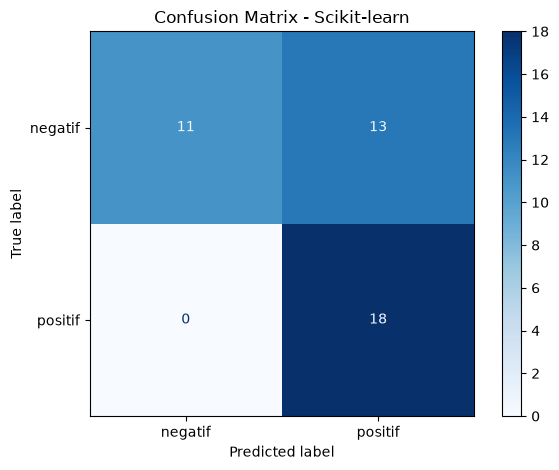

In [9]:
LABELS = ['negatif','positif']
print('=== Model Klasik (Scikit-learn) ===')
print(classification_report(y_test, y_pred_classic, labels=LABELS, zero_division=0))
print('Accuracy:',round(accuracy_score(y_test,y_pred_classic),4))
print('Confusion matrix (negatif, positif):\n',confusion_matrix(y_test,y_pred_classic,labels=LABELS))
ConfusionMatrixDisplay.from_predictions(y_test,y_pred_classic,labels=LABELS,cmap='Blues',values_format='d')
plt.title('Confusion Matrix - Scikit-learn')
plt.tight_layout()
plt.savefig(DOCS_PATH / 'confusion_matrix_classic.png',dpi=140)
plt.show()


### 6.2 Evaluasi LLM API

=== LLM API (Gemini) ===
              precision    recall  f1-score   support

     negatif       1.00      1.00      1.00        24
     positif       1.00      1.00      1.00        18

    accuracy                           1.00        42
   macro avg       1.00      1.00      1.00        42
weighted avg       1.00      1.00      1.00        42

Accuracy: 1.0
Confusion matrix (negatif, positif):
 [[24  0]
 [ 0 18]]


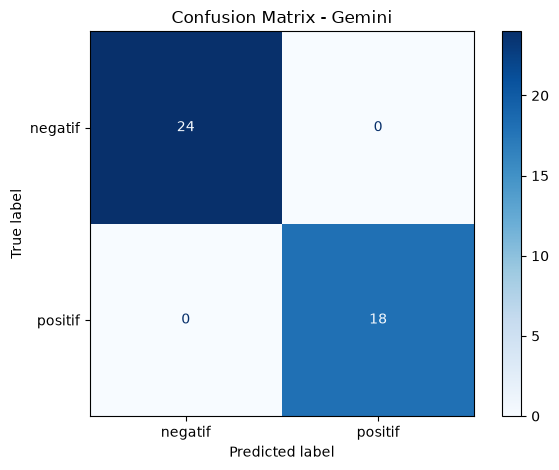

In [10]:
print('=== LLM API (Gemini) ===')
print(classification_report(y_test,y_pred_llm,labels=LABELS,zero_division=0))
print('Accuracy:',round(accuracy_score(y_test,y_pred_llm),4))
print('Confusion matrix (negatif, positif):\n',confusion_matrix(y_test,y_pred_llm,labels=LABELS))
ConfusionMatrixDisplay.from_predictions(y_test,y_pred_llm,labels=LABELS,cmap='Blues',values_format='d')
plt.title('Confusion Matrix - Gemini')
plt.tight_layout()
plt.savefig(DOCS_PATH / 'confusion_matrix_gemini.png',dpi=140)
plt.show()


### 6.3 Tabel Perbandingan Ringkasan

,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,TF-IDF + Logistic Regression,0.6905,0.7903,0.7292,0.6816
1,Gemini API (gemini-3.5-flash-lite),1.0000,1.0000,1.0000,1.0000


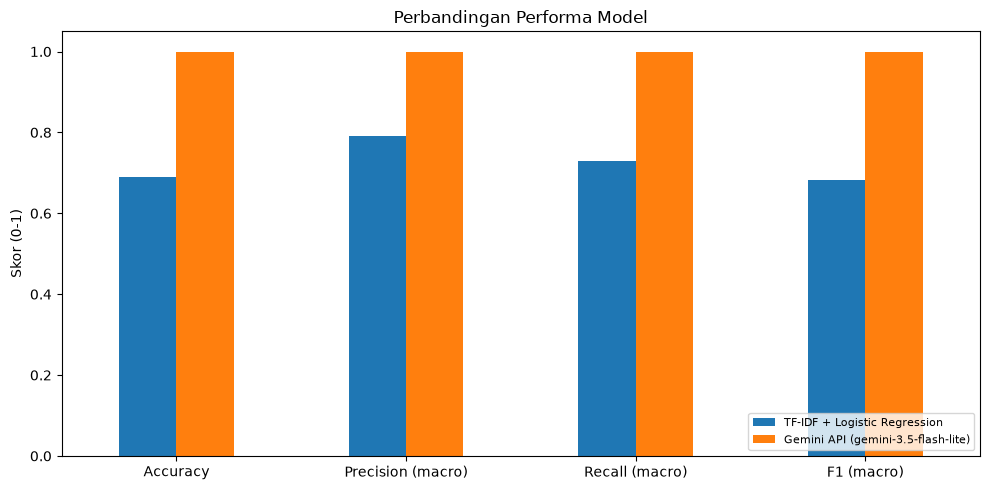

In [11]:
def evaluate(name, y_true, y_prediction):
    return {
        'Model':name,
        'Accuracy':accuracy_score(y_true,y_prediction),
        'Precision (macro)':precision_score(y_true,y_prediction,labels=LABELS,average='macro',zero_division=0),
        'Recall (macro)':recall_score(y_true,y_prediction,labels=LABELS,average='macro',zero_division=0),
        'F1 (macro)':f1_score(y_true,y_prediction,labels=LABELS,average='macro',zero_division=0)
    }
summary = pd.DataFrame([
    evaluate('TF-IDF + Logistic Regression',y_test,y_pred_classic),
    evaluate(f'Gemini API ({MODEL_NAME})',y_test,y_pred_llm)
])
display(summary.round(4))
summary.to_csv(DOCS_PATH/'evaluation_summary.csv',index=False)

predictions = test_df[['review_id','product_name','review_text','sentiment']].copy()
predictions['pred_classic'] = y_pred_classic
predictions['pred_gemini'] = y_pred_llm
predictions['classic_correct'] = predictions['sentiment'] == predictions['pred_classic']
predictions['gemini_correct'] = predictions['sentiment'] == predictions['pred_gemini']
predictions.to_csv(DOCS_PATH/'test_predictions.csv',index=False,encoding='utf-8-sig')

ax = summary.set_index('Model')[['Accuracy','Precision (macro)','Recall (macro)','F1 (macro)']].T.plot.bar(figsize=(10,5),rot=0)
ax.set_ylabel('Skor (0-1)')
ax.set_ylim(0,1.05)
ax.set_title('Perbandingan Performa Model')
ax.legend(loc='lower right',fontsize=8)
plt.tight_layout()
plt.savefig(DOCS_PATH/'model_comparison_summary.png',dpi=150)
plt.show()


### 6.4 Analisis Kesalahan (Error Analysis)

In [12]:
errors = predictions.loc[(~predictions['classic_correct']) | (~predictions['gemini_correct'])]
print('Jumlah baris dengan minimal satu prediksi salah:',len(errors))
display(errors[['review_text','sentiment','pred_classic','pred_gemini']].drop_duplicates().head(15))


Jumlah baris dengan minimal satu prediksi salah: 13


,review_text,sentiment,pred_classic,pred_gemini
23,Respon penjual lambat dan terkesan tidak pedul...,negatif,positif,negatif
30,"Ukuran dan warna berbeda dari pesanan, sangat ...",negatif,positif,negatif


## 7. Analisis Trade-off dan Limitation

### 7.1 Analisis performa kedua pendekatan

Eksperimen dilakukan menggunakan **dataset yang sama**, yaitu 200 baris ulasan berbahasa Indonesia dengan **40 teks unik**. Pemisahan data dibuat berdasarkan teks unik agar teks ulasan yang identik tidak muncul sekaligus di data training dan testing. Hasilnya, model klasik dilatih pada **158 baris (32 teks unik)** dan kedua model diuji pada **42 baris (8 teks unik)**, terdiri atas 24 ulasan negatif dan 18 ulasan positif.

| Metrik evaluasi | TF-IDF + Logistic Regression | Gemini API (`gemini-3.5-flash-lite`) |
|---|---:|---:|
| Accuracy | 69,05% | **100,00%** |
| Precision (macro) | 79,03% | **100,00%** |
| Recall (macro) | 72,92% | **100,00%** |
| F1-Score (macro) | 68,16% | **100,00%** |
| Prediksi benar | 29 dari 42 | **42 dari 42** |
| Prediksi salah | 13 dari 42 | **0 dari 42** |

**Interpretasi:** Pada test set yang digunakan, Gemini API memiliki **Accuracy lebih tinggi 30,95 poin persentase** dan **F1-Score (macro) lebih tinggi 31,84 poin persentase** dibandingkan model klasik. Nilai F1-macro penting karena merangkum keseimbangan precision dan recall pada kedua kelas. Hasil ini menunjukkan bahwa **Gemini lebih baik dalam eksperimen ini**, tetapi belum cukup untuk menyimpulkan bahwa Gemini selalu memiliki akurasi 100% pada ulasan pelanggan lain.

### 7.2 Analisis confusion matrix dan kesalahan prediksi

- **Scikit-learn:** Confusion matrix `[[11, 13], [0, 18]]` dengan urutan kelas `[negatif, positif]`. Artinya, **11 ulasan negatif** diklasifikasikan benar, **13 ulasan negatif** salah diprediksi sebagai positif, **18 ulasan positif** diklasifikasikan benar, dan **tidak ada ulasan positif** yang salah diprediksi sebagai negatif. Recall kelas negatif hanya **0,46 (46%)**, sementara recall kelas positif adalah **1,00 (100%)**. Ini menunjukkan bahwa model klasik cenderung kesulitan mengenali sebagian ungkapan ketidakpuasan pelanggan.
- **Gemini API:** Confusion matrix `[[24, 0], [0, 18]]`. Seluruh **24 ulasan negatif** dan **18 ulasan positif** diprediksi benar; tidak ditemukan kesalahan pada test set ini.
- **Error analysis:** Terdapat **13 baris** yang salah diklasifikasikan model klasik, tetapi baris tersebut berasal dari **2 teks negatif yang berbeda**. Contoh yang terlihat pada hasil notebook adalah ulasan mengenai **respons penjual yang lambat/tidak peduli** dan **ukuran/warna produk yang tidak sesuai pesanan**. Model klasik memprediksi kedua jenis keluhan tersebut sebagai positif, sedangkan Gemini memprediksi negatif dengan benar.

**Implikasi bisnis:** Pada fitur analisis ulasan e-commerce, kesalahan menganggap keluhan sebagai ulasan positif berpotensi membuat tim produk melewatkan ketidakpuasan pelanggan. Karena itu, kemampuan mengenali kelas negatif (recall negatif) perlu mendapat perhatian, tidak hanya accuracy keseluruhan.

### 7.3 Trade-off implementasi, kecepatan, dan biaya

| Aspek | TF-IDF + Logistic Regression | Gemini API (zero-shot) |
|---|---|---|
| **Effort implementasi** | Memerlukan pembagian data, ekstraksi fitur TF-IDF, training model, serta evaluasi; model perlu dilatih ulang jika data berkembang. | Tidak membutuhkan training dataset; memerlukan perancangan prompt, API key, koneksi API, validasi output, dan penanganan error/rate limit. |
| **Kecepatan** | Inferensi berlangsung secara lokal tanpa request jaringan. Notebook mencatat waktu **training sekitar 0,0149 detik**; waktu inferensi spesifik tidak ditampilkan dalam output. | Notebook mencatat **33,29 detik** untuk loop **8 panggilan API baru**, tetapi waktu tersebut **termasuk jeda terprogram 3 detik per panggilan**, sehingga **bukan ukuran latency API murni** dan tidak dapat langsung dibandingkan dengan waktu training model klasik. |
| **Biaya** | Tidak membutuhkan biaya pemanggilan API, namun tetap membutuhkan sumber daya perangkat, pemeliharaan model, dan training ulang. | Dapat menimbulkan biaya pemakaian API sesuai kuota/tier dan jumlah token; biaya aktual tidak dicatat dalam notebook sehingga belum dapat dihitung secara pasti. |
| **Ketergantungan sistem** | Model dapat dijalankan secara lokal tanpa ketergantungan internet ketika inferensi. | Memerlukan koneksi ke layanan eksternal, API key aktif, serta pengelolaan rate limit dan potensi gangguan layanan. |
| **Kontrol dan data** | Lebih mudah menjaga pemrosesan ulasan tetap pada infrastruktur internal. | Perlu menilai kebijakan privasi, pengiriman data ke pihak ketiga, dan persyaratan keamanan sebelum digunakan dalam produksi. |

### 7.4 Limitation (keterbatasan eksperimen)

1. **Variasi data terbatas:** Dari total 200 baris, hanya terdapat **40 teks ulasan unik**. Walaupun pemisahan berdasarkan teks unik mengurangi risiko kebocoran antara training dan testing, 42 baris test set sebenarnya hanya terdiri dari **8 variasi kalimat unik**. Pengulangan kalimat dapat membuat metrik tampak lebih meyakinkan daripada kemampuan generalisasi yang sebenarnya.
2. **Belum mewakili seluruh ulasan produksi:** Dataset hanya mencakup dua label (`positif` dan `negatif`) dan belum secara memadai menguji kasus **netral, ambigu, sarkasme, bahasa gaul, campuran bahasa**, maupun ulasan yang memuat beberapa sentimen sekaligus.
3. **Keterbatasan model klasik:** TF-IDF + Logistic Regression mengandalkan pola kata dari data training yang kecil; pada test set ini masih terjadi **13 false positive terhadap kelas positif** (13 keluhan negatif salah dianggap positif).
4. **Keterbatasan Gemini:** Hasil **100%** hanya berlaku untuk test set ini, bukan bukti akurasi produksi. Respons LLM dapat dipengaruhi prompt, versi model, batas kuota, layanan eksternal, dan kondisi jaringan. Hanya **8 teks unik** diproses melalui cache; stabilitas prediksi pada pengulangan dan data baru belum diuji.
5. **Belum ada pengukuran biaya dan latency API yang terpisah:** Notebook tidak mencatat token usage atau biaya riil. Waktu loop Gemini mencakup jeda sengaja, sehingga belum dapat menjadi dasar estimasi SLA atau perhitungan biaya produksi.

**Kesimpulan Section 7:** Pada eksperimen ini, **Gemini API unggul dalam kualitas klasifikasi**, terutama dalam mengenali keluhan negatif yang gagal diidentifikasi model klasik. Sebaliknya, **Scikit-learn lebih sederhana untuk inferensi lokal dan tidak memiliki biaya API per pemanggilan**. Perbedaan performa yang cukup besar mendukung pemilihan Gemini untuk eksperimen lanjutan, dengan tetap memperhatikan keterbatasan dataset, latency, biaya, dan aspek privasi.


## 8. Rekomendasi Technical Approach

### 8.1 Pendekatan yang direkomendasikan: Gemini API untuk tahap pengembangan lanjutan (*pilot*)

Berdasarkan hasil pada Section 6 dan analisis Section 7, **Gemini API (`gemini-3.5-flash-lite`) direkomendasikan dengan pendekatan zero-shot prompting sebagai kandidat utama untuk pengembangan lebih lanjut pada use case sentiment analysis ulasan pelanggan e-commerce**. Rekomendasi ini ditujukan untuk **pilot/proof of concept**, bukan keputusan langsung menerapkan model tanpa pengujian tambahan ke sistem produksi.

**Alasan utama:**

1. **Performa evaluasi lebih baik:** Gemini memperoleh **Accuracy, Precision (macro), Recall (macro), dan F1-Score (macro) sebesar 100%**, dibandingkan model klasik dengan **Accuracy 69,05%** dan **F1-Score (macro) 68,16%** pada **test set identik (42 baris, 8 teks unik)**.
2. **Lebih baik mengenali sentimen negatif:** Gemini mengenali semua **24 ulasan negatif** pada test set; model klasik hanya benar pada **11 dari 24**, sementara **13 ulasan negatif** salah diklasifikasikan sebagai positif. Bagi tim e-commerce, kesalahan mendeteksi keluhan dapat mengganggu tindak lanjut masalah pelanggan.
3. **Tidak memerlukan training model:** Gemini dapat langsung digunakan melalui prompt yang sudah dibuat, yaitu menetapkan dua label valid (`positif` dan `negatif`) dan `temperature=0,0`. Ini mempermudah pengembangan awal tanpa membangun pipeline pelatihan model sendiri.
4. **Namun belum cukup untuk produksi:** Keunggulan tersebut baru terbukti pada **8 teks ulasan unik dalam test set**. Sebelum diimplementasikan secara luas, performa harus diuji pada ulasan nyata yang lebih bervariasi, sambil memeriksa biaya token, waktu respons API, dan persyaratan privasi.

### 8.2 Rencana tindak lanjut sebelum produksi

1. **Perluas dataset dan evaluasi:** Kumpulkan lebih banyak ulasan yang **benar-benar unik dan representatif**, termasuk kasus negatif, positif, ambigu, typo, sarkasme, serta variasi bahasa. Pertahankan pemisahan training/test berdasarkan teks atau kelompok duplikat dan evaluasi pada test set baru yang belum pernah digunakan untuk menyetel prompt atau model.
2. **Uji performa Gemini secara operasional:** Ukur latency *request* API tanpa jeda buatan, tingkat error/rate limit, pemakaian token, estimasi biaya per 1.000/10.000 ulasan, dan konsistensi prediksi. Gunakan parameter prompt dan versi model yang terdokumentasi.
3. **Tinjau keamanan data:** Pastikan data ulasan yang dikirim ke layanan eksternal sesuai kebijakan organisasi; identifikasi dan tangani informasi pribadi yang mungkin muncul pada ulasan.
4. **Tentukan target kelayakan bisnis:** Sepakati ambang minimum F1-Score, terutama recall kelas negatif, serta batas biaya dan waktu respons. Gunakan hasil pengujian tambahan untuk menentukan apakah Gemini layak masuk produksi.
5. **Siapkan opsi efisiensi/fallback:** Scikit-learn dapat dikembangkan kembali dengan dataset lebih besar, fitur yang ditingkatkan, dan tuning. Pendekatan **hybrid** (model lokal untuk kasus berkeyakinan tinggi, Gemini untuk kasus sulit) juga bisa dipertimbangkan, tetapi **belum diuji pada assignment ini** sehingga bukan hasil eksperimen yang sudah terbukti.

### 8.3 Kesimpulan akhir

**Gemini API merupakan pendekatan yang paling menjanjikan berdasarkan eksperimen yang telah dijalankan** karena menghasilkan **42 prediksi benar dari 42 baris test set**, sementara model klasik benar pada **29 dari 42 baris**. Keunggulan Gemini terutama terlihat pada kemampuan mengenali ulasan negatif. **Saya merekomendasikan Gemini untuk pilot lanjutan**, sedangkan Scikit-learn dipertahankan sebagai baseline dan alternatif yang berpotensi lebih hemat biaya.
